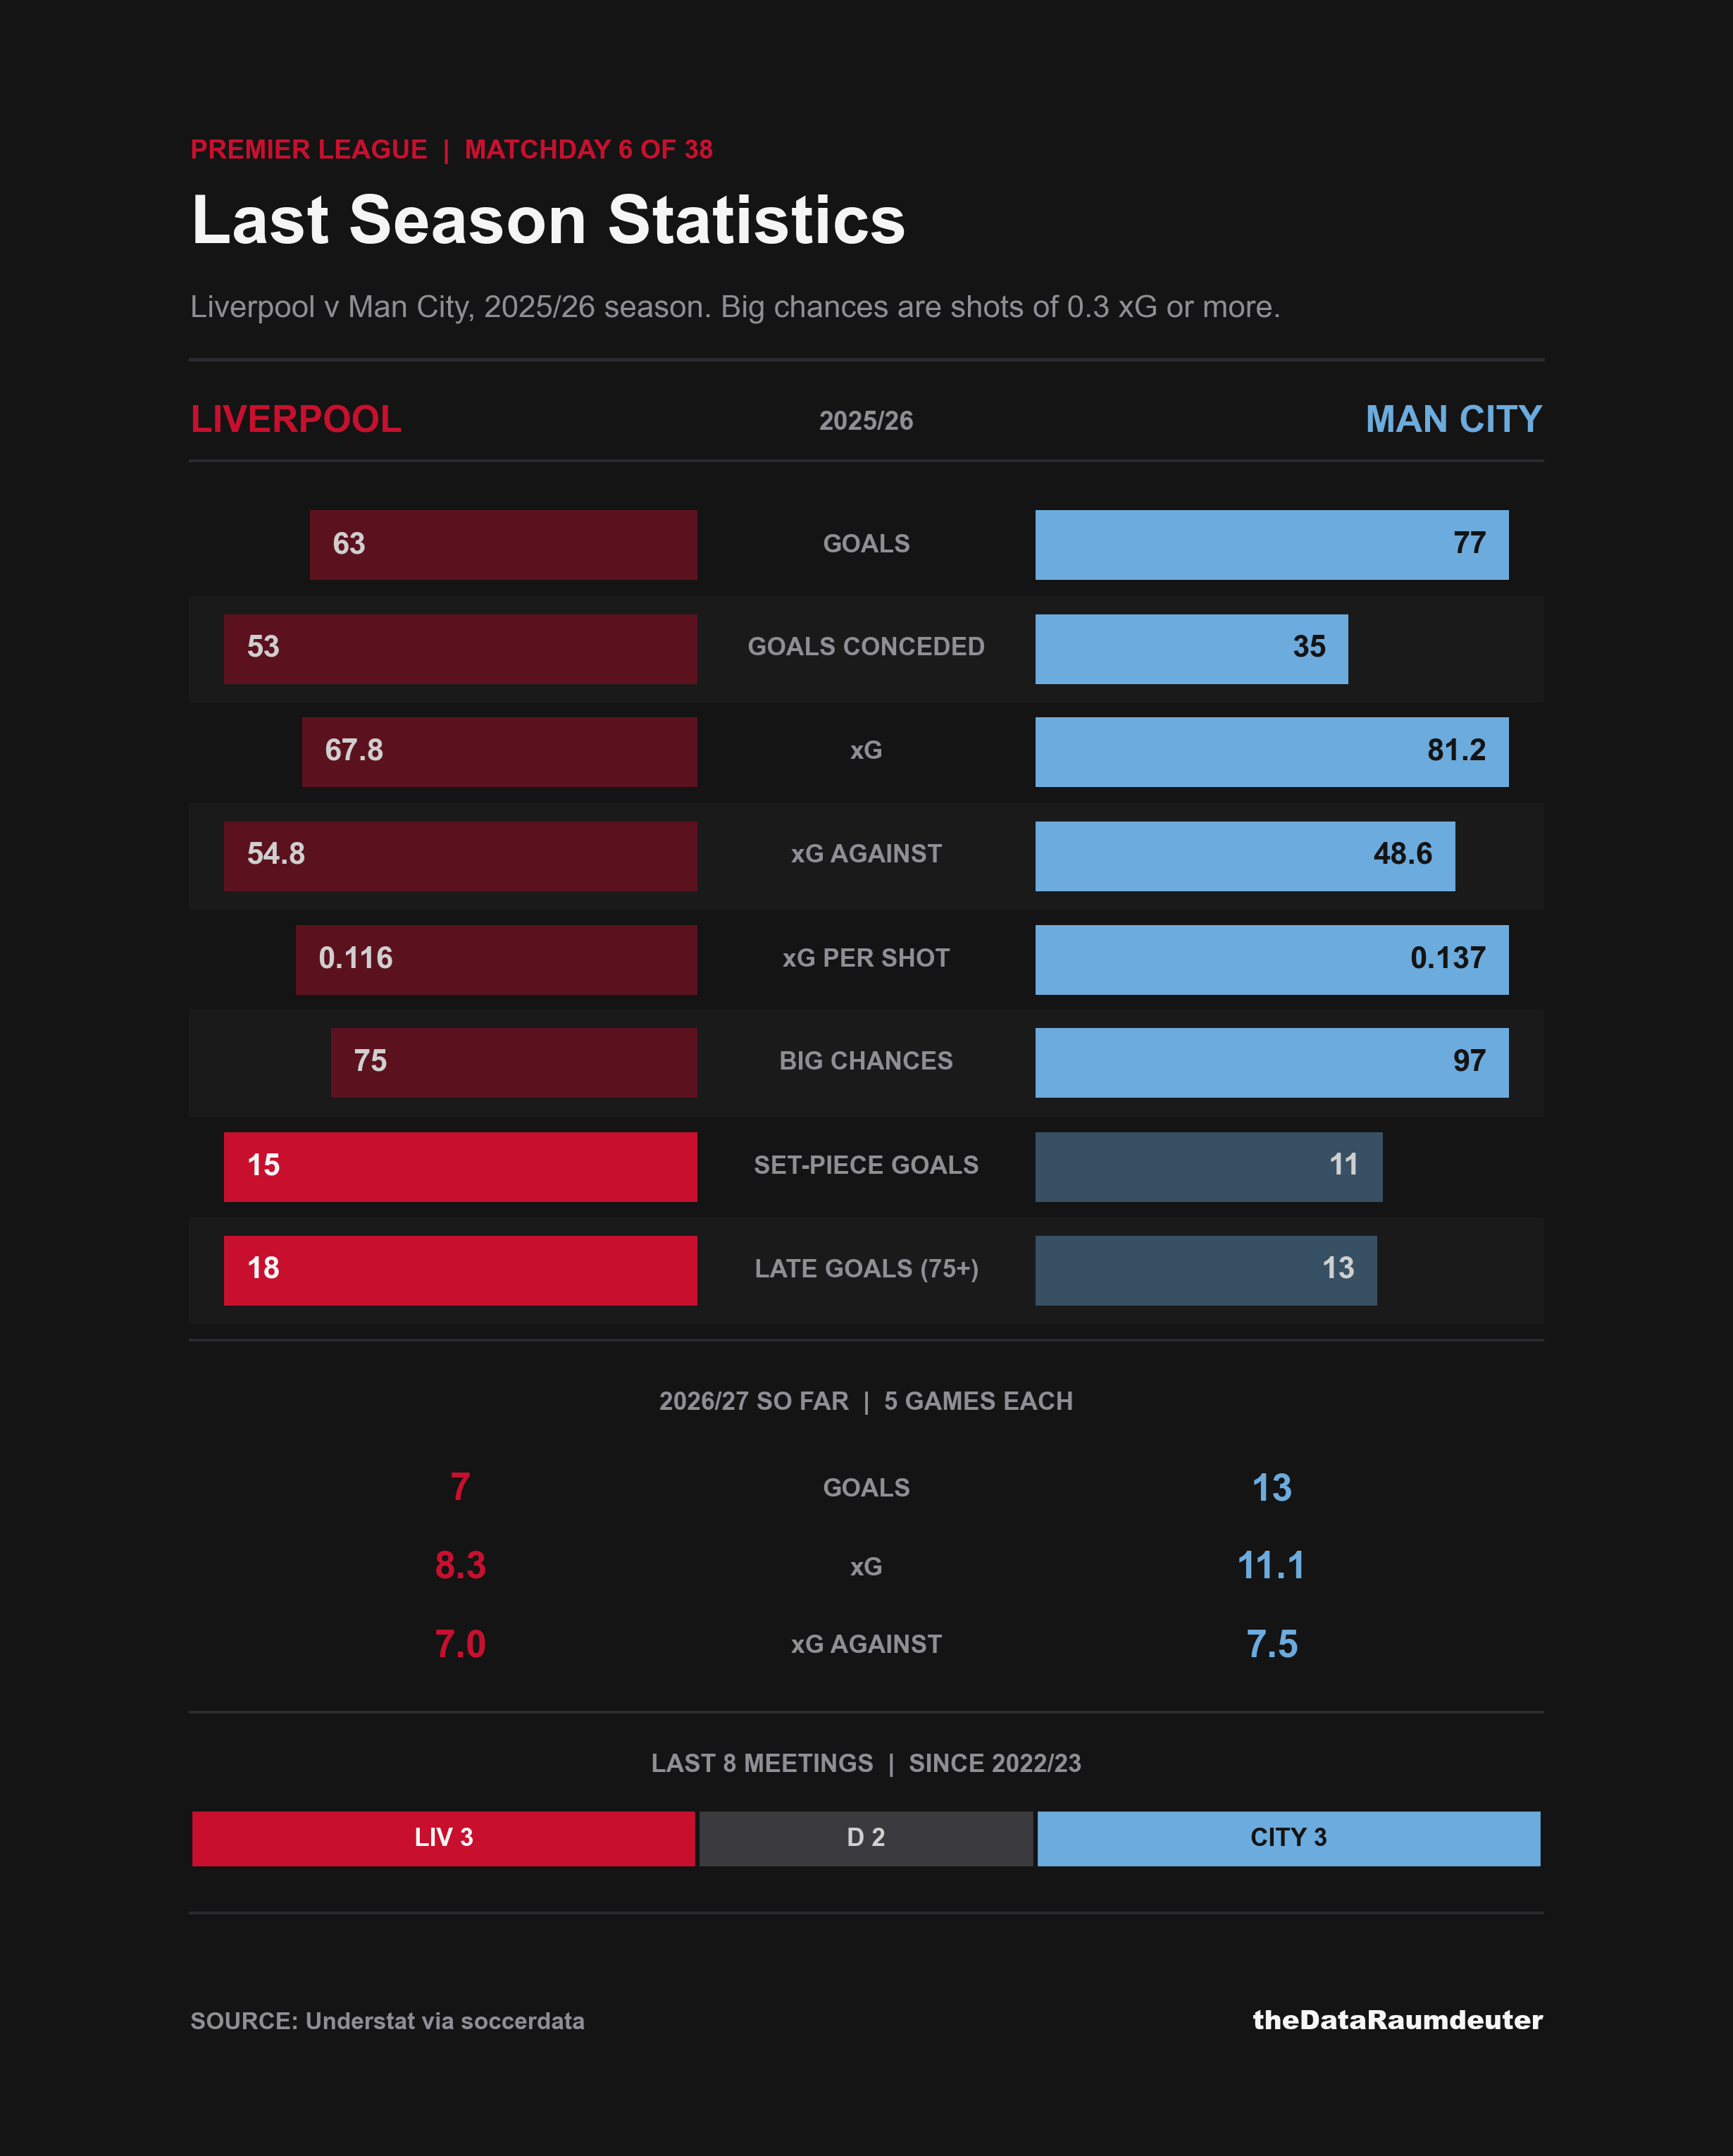

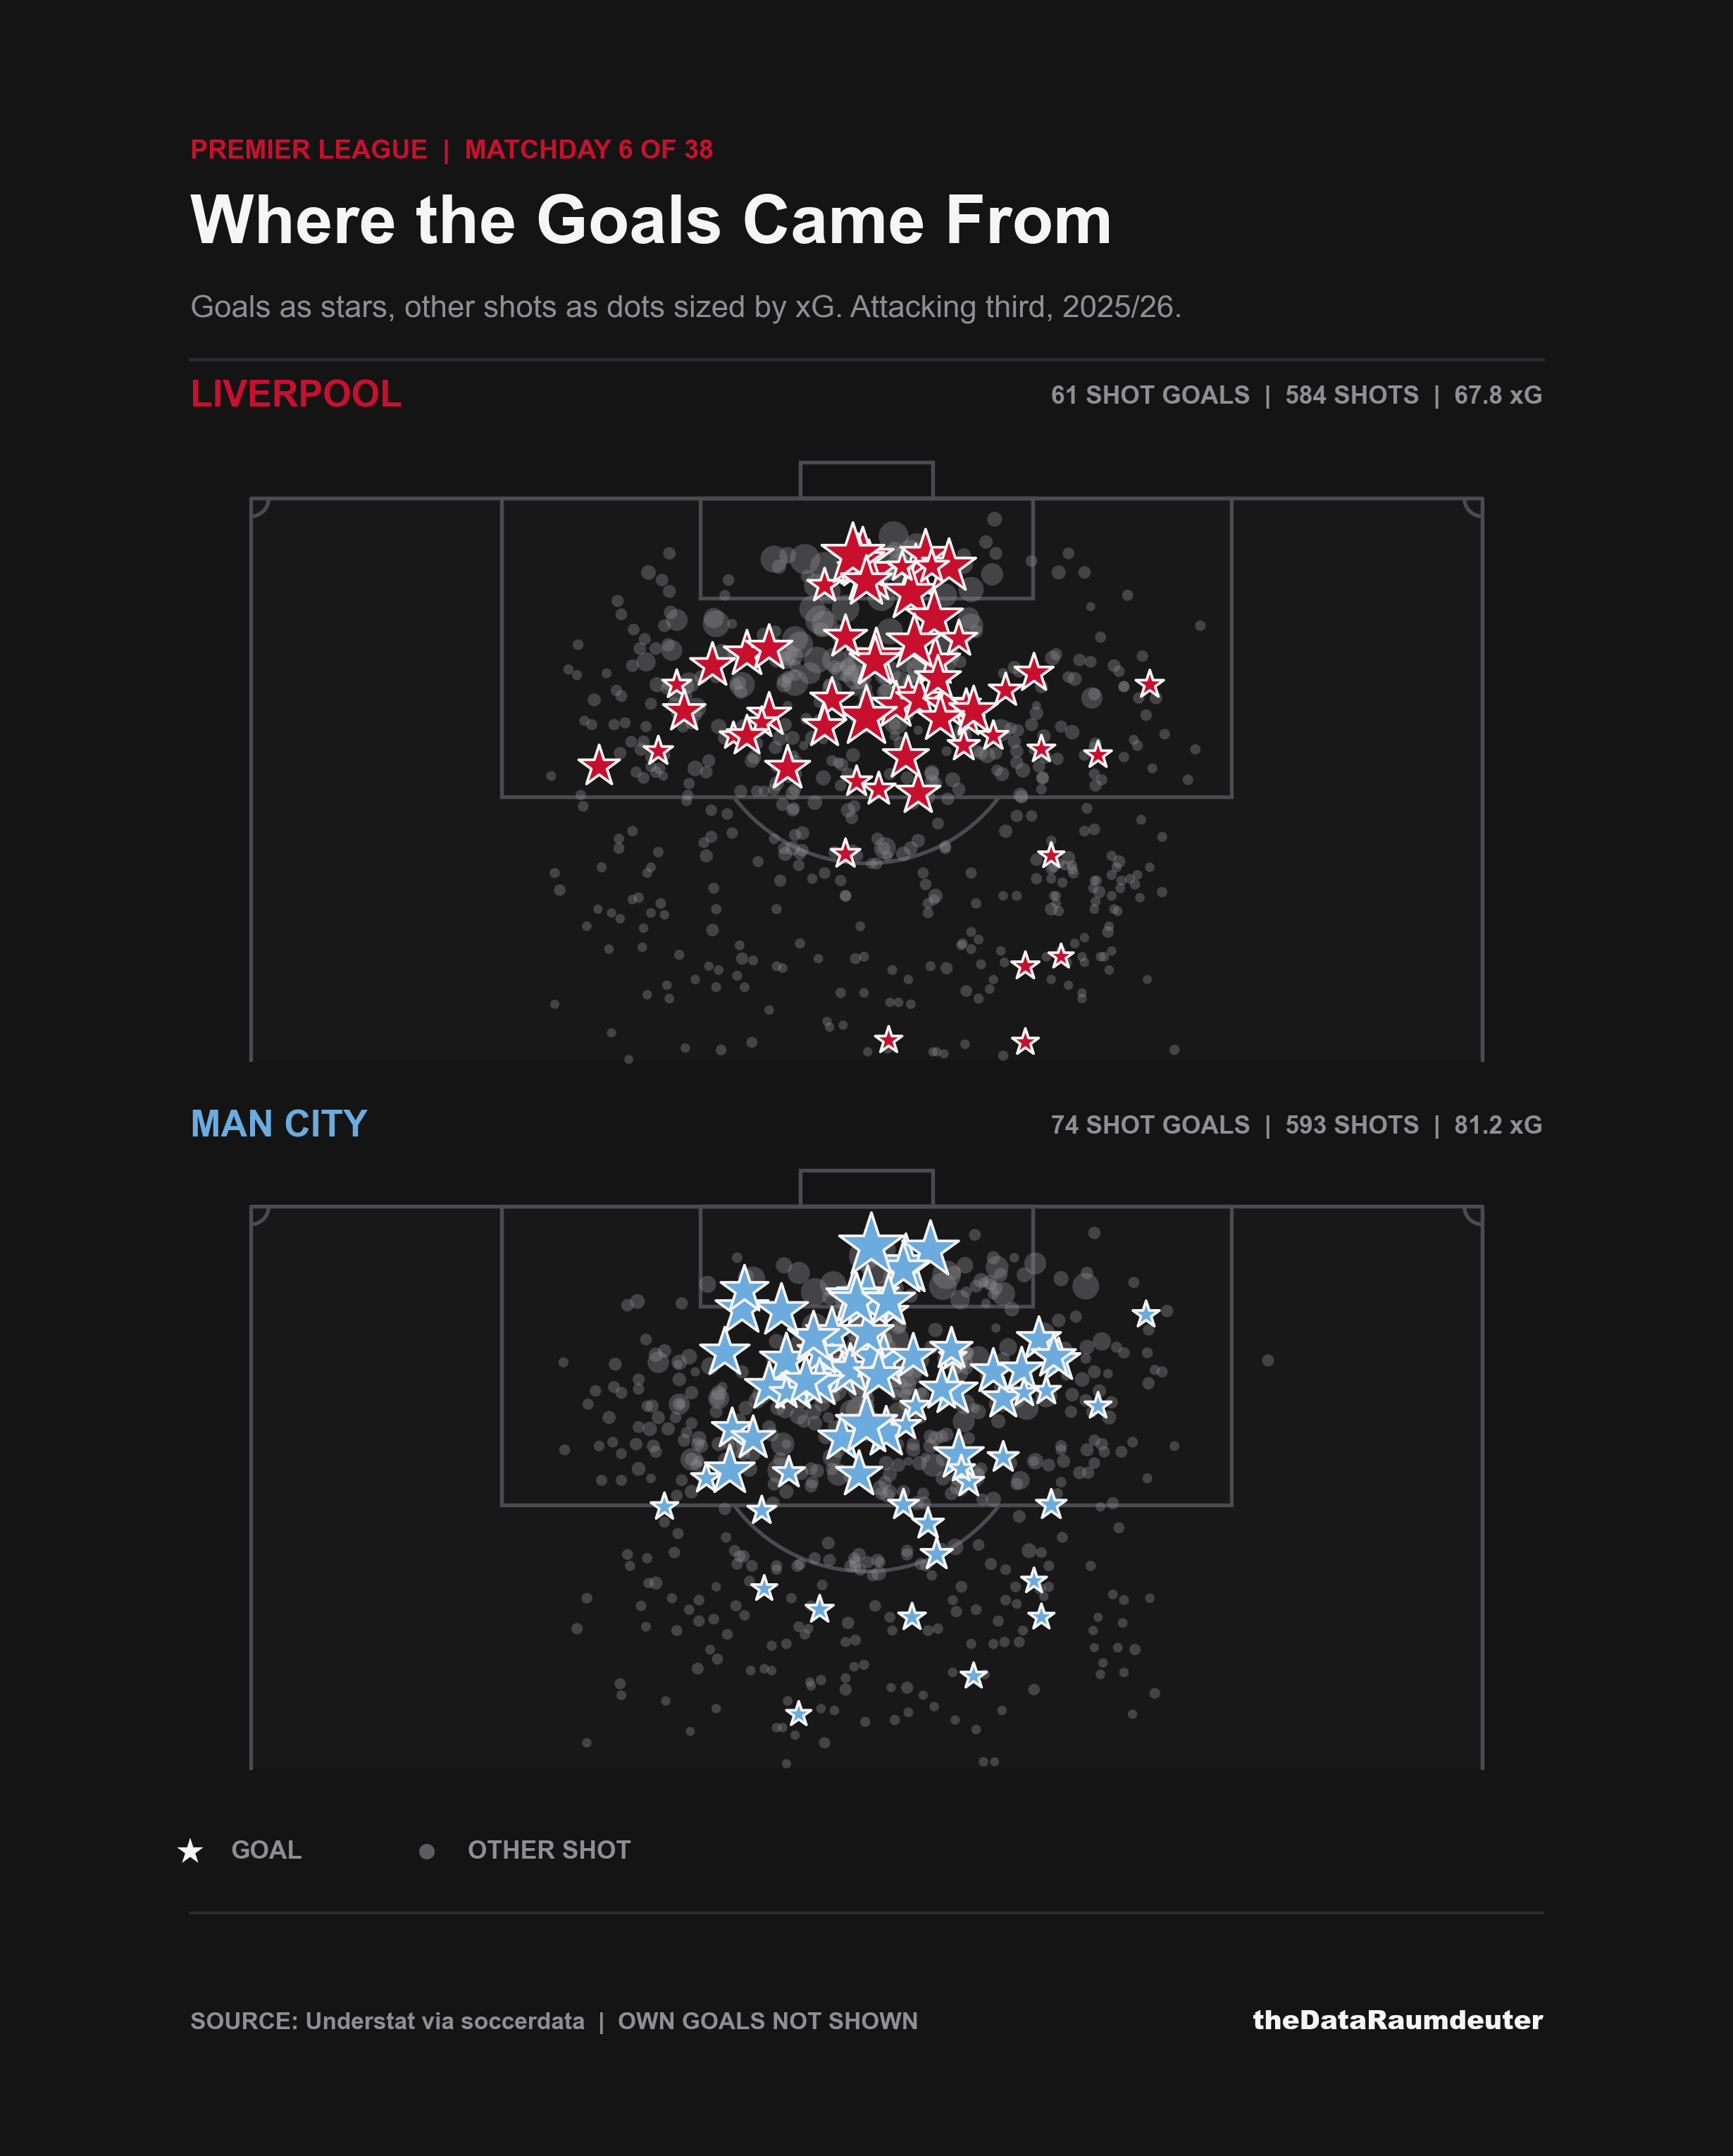

In [2]:
import html

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Arc, Circle, Rectangle

# ------------------------------------------------------------------
# CONFIG (change these per post)
# ------------------------------------------------------------------
CSV = "datasets/shot_events.csv"          # path to your shot events file
HOME, AWAY = "Liverpool", "Manchester City"
SHORT = {"Liverpool": "LIVERPOOL", "Manchester City": "MAN CITY"}
SEASON, SEASON_LABEL = 2526, "2025/26"
CURRENT, CURRENT_LABEL = 2627, "2026/27"
KICKER = "PREMIER LEAGUE  |  MATCHDAY 6 OF 38"
SOURCE = "SOURCE: Understat via soccerdata"

# ------------------------------------------------------------------
# FIXED THEME
# ------------------------------------------------------------------
THEME = {
    "bg": "#141414", "border": "#2A2A2E", "accent": "#D10022", "white": "#F5F5F5",
    "muted": "#8E8E93", "zebra": "#1A1A1A", "row_text": "#CFCFCF", "neutral": "#3A3A3F",
    "pitch_fill": "#181818", "pitch_line": "#4A4A50",
}
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Inter", "Graphik", "Helvetica Neue", "Arial", "DejaVu Sans"]
PITCH_L, PITCH_W = 105.0, 68.0

# Only the accent changes per team (tuned to read on charcoal)
TEAM_ACCENT = {
    "Arsenal": "#EF0107", "Aston Villa": "#95BFE5", "Bournemouth": "#DA291C",
    "Brentford": "#E30613", "Brighton": "#3D8BFD", "Burnley": "#99D6EA",
    "Chelsea": "#2E6FD8", "Coventry": "#5CB8E6", "Crystal Palace": "#C4122E",
    "Everton": "#3B6FD4", "Fulham": "#CC0000", "Hull": "#F5A21A",
    "Ipswich": "#3A64D8", "Leeds": "#FFCD00", "Leicester": "#4F8FE0",
    "Liverpool": "#C8102E", "Luton": "#F78F1E", "Manchester City": "#6CABDD",
    "Manchester United": "#DA291C", "Newcastle United": "#41B6E6",
    "Nottingham Forest": "#E53233", "Sheffield United": "#EE2737",
    "Southampton": "#D71920", "Sunderland": "#EB172B", "Tottenham": "#8FA8E8",
    "West Ham": "#8DC3EB", "Wolverhampton Wanderers": "#FDB913",
}


def accent_for(team):
    return TEAM_ACCENT.get(team, THEME["accent"])


def _rgb(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) for i in (0, 2, 4))


def mix(fg, bg, a):
    return "#%02X%02X%02X" % tuple(round(a * x + (1 - a) * y) for x, y in zip(_rgb(fg), _rgb(bg)))


def text_on(color):
    r, g, b = _rgb(color)
    return THEME["bg"] if (0.299 * r + 0.587 * g + 0.114 * b) / 255 > 0.6 else THEME["white"]


# ------------------------------------------------------------------
# CHROME: canvas, header deck, divider, footer
# ------------------------------------------------------------------
def new_canvas():
    fig = plt.figure(figsize=(8, 10), dpi=300)
    fig.patch.set_facecolor(THEME["bg"])
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_facecolor(THEME["bg"])
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.axis("off")
    return fig, ax


def header(fig, kicker, title, subtitle, accent):
    t = THEME
    fig.text(0.10, 0.935, kicker, fontsize=9, fontweight="bold", color=accent, ha="left")
    fig.text(0.10, 0.895, title, fontsize=23, fontweight="heavy", color=t["white"], ha="left")
    fig.text(0.10, 0.860, subtitle, fontsize=10.5, color=t["muted"], ha="left")


def divider(ax, y, lw=1.0):
    ax.plot([10, 90], [y, y], color=THEME["border"], lw=lw)


def footer(fig, ax, source, brand="theDataRaumdeuter"):
    t = THEME
    divider(ax, 10.5)
    fig.text(0.10, 0.05, source, fontsize=8, color=t["muted"], ha="left", fontweight="semibold")
    fig.text(0.90, 0.05, brand, fontsize=9, color=t["white"], ha="right", fontweight="black")


def draw_pitch(ax, y_min=PITCH_L / 2):
    """Vertical pitch, attacking up; y_min trims it from the bottom."""
    t = THEME
    c, lw, cx = t["pitch_line"], 1.3, PITCH_W / 2
    ax.add_patch(Rectangle((0, y_min), PITCH_W, PITCH_L - y_min, fc=t["pitch_fill"], ec="none", zorder=0))
    ax.plot([0, 0, PITCH_W, PITCH_W], [y_min, PITCH_L, PITCH_L, y_min], color=c, lw=lw, zorder=1)
    if y_min <= PITCH_L / 2:
        ax.plot([0, PITCH_W], [PITCH_L / 2] * 2, color=c, lw=lw, zorder=1)
        ax.add_patch(Arc((cx, PITCH_L / 2), 18.3, 18.3, theta1=0, theta2=180, ec=c, lw=lw, zorder=1))
    ax.add_patch(Rectangle((cx - 20.16, PITCH_L - 16.5), 40.32, 16.5, fill=False, ec=c, lw=lw, zorder=1))
    ax.add_patch(Rectangle((cx - 9.16, PITCH_L - 5.5), 18.32, 5.5, fill=False, ec=c, lw=lw, zorder=1))
    ax.add_patch(Rectangle((cx - 3.66, PITCH_L), 7.32, 2.0, fill=False, ec=c, lw=lw, zorder=1))
    ax.add_patch(Circle((cx, PITCH_L - 11), 0.35, color=c, zorder=1))
    ax.add_patch(Arc((cx, PITCH_L - 11), 18.3, 18.3, theta1=216.87, theta2=323.13, ec=c, lw=lw, zorder=1))
    ax.add_patch(Arc((0, PITCH_L), 2, 2, theta1=270, theta2=360, ec=c, lw=lw, zorder=1))
    ax.add_patch(Arc((PITCH_W, PITCH_L), 2, 2, theta1=180, theta2=270, ec=c, lw=lw, zorder=1))
    ax.set_xlim(-2, PITCH_W + 2)
    ax.set_ylim(y_min - (2.5 if y_min <= PITCH_L / 2 else 1.0), PITCH_L + 3)
    ax.set_aspect("equal")
    ax.axis("off")


# ------------------------------------------------------------------
# DATA
# ------------------------------------------------------------------
def load(path):
    df = pd.read_csv(path, parse_dates=["date"])
    for c in ("team", "player", "assist_player", "game"):
        df[c] = df[c].map(lambda s: html.unescape(s) if isinstance(s, str) else s)
    df["goal"] = (df["result"] == "Goal").astype(int)
    return df


def team_stats(df, season, team):
    """Season totals for `team` (own goals count as goals, never as shots)."""
    s = df[df.season == season]
    games = s[s.team == team].game_id.unique()
    g = s[s.game_id.isin(games)]
    shots, own = g[g.result != "Own Goal"], g[g.result == "Own Goal"]
    f, a = shots[shots.team == team], shots[shots.team != team]
    set_piece = f.situation.isin(["From Corner", "Set Piece", "Direct Freekick"])
    return {
        "games": len(games),
        "goals": f.goal.sum() + (own.team != team).sum(),
        "goals_against": a.goal.sum() + (own.team == team).sum(),
        "xg": f.xg.sum(), "xga": a.xg.sum(), "shots": len(f),
        "xg_per_shot": f.xg.sum() / len(f),
        "big": int((f.xg >= 0.3).sum()),
        "sp_goals": int(f[set_piece].goal.sum()),
        "late": int(f[f.minute >= 75].goal.sum()),
    }


def head_to_head(df, a, b):
    """(a wins, draws, b wins, meetings) across every meeting in the data."""
    wa = wb = dr = n = 0
    for _, x in df.groupby("game_id"):
        if not {a, b} <= set(x.team):
            continue
        ga = ((x.team == a) & (x.result == "Goal")).sum() + ((x.team == b) & (x.result == "Own Goal")).sum()
        gb = ((x.team == b) & (x.result == "Goal")).sum() + ((x.team == a) & (x.result == "Own Goal")).sum()
        n += 1
        wa += ga > gb
        wb += gb > ga
        dr += ga == gb
    return int(wa), int(dr), int(wb), n


# ------------------------------------------------------------------
# SLIDE 1: HEAD TO HEAD
# ------------------------------------------------------------------
METRICS = [  # label, key, format, higher is better
    ("GOALS",            "goals",         "{:.0f}", True),
    ("GOALS CONCEDED",   "goals_against", "{:.0f}", False),
    ("xG",               "xg",            "{:.1f}", True),
    ("xG AGAINST",       "xga",           "{:.1f}", False),
    ("xG PER SHOT",      "xg_per_shot",   "{:.3f}", True),
    ("BIG CHANCES",      "big",           "{:.0f}", True),
    ("SET-PIECE GOALS",  "sp_goals",      "{:.0f}", True),
    ("LATE GOALS (75+)", "late",          "{:.0f}", True),
]


def slide_head_to_head(s_a, s_b, now_a, now_b, h2h, outfile):
    t = THEME
    ca, cb = accent_for(HOME), accent_for(AWAY)
    fig, ax = new_canvas()
    header(fig, KICKER, "Last Season Statistics",
           f"{SHORT[HOME].title()} v {SHORT[AWAY].title()}, {SEASON_LABEL} season. "
           "Big chances are shots of 0.3 xG or more.", ca)
    divider(ax, 84, 1.2)

    ax.text(10, 81.0, SHORT[HOME], fontsize=12.5, color=ca, weight="heavy", ha="left", va="center")
    ax.text(90, 81.0, SHORT[AWAY], fontsize=12.5, color=cb, weight="heavy", ha="right", va="center")
    ax.text(50, 81.0, SEASON_LABEL, fontsize=9, color=t["muted"], weight="bold", ha="center", va="center")
    divider(ax, 79.2)

    start_y, step, half = 75.2, 4.9, 2.45
    inner, max_len = 10.0, 28.0
    left_edge, right_edge = 50 - inner, 50 + inner
    for i, (label, key, fmt, higher) in enumerate(METRICS):
        y = start_y - i * step
        if i % 2 == 1:
            ax.fill_between([10, 90], y - half, y + half, color=t["zebra"], zorder=0)
        va_, vb_ = float(s_a[key]), float(s_b[key])
        top = max(va_, vb_)
        best = va_ if higher and va_ >= vb_ else vb_ if higher else min(va_, vb_)
        ax.text(50, y, label, fontsize=8.5, color=t["muted"], weight="bold", ha="center", va="center")
        for val, color, side in ((va_, ca, "L"), (vb_, cb, "R")):
            win = val == best
            fill = color if win else mix(color, t["bg"], 0.40)
            txt = text_on(color) if win else t["row_text"]
            length = val / top * max_len
            if side == "L":
                ax.barh(y, -length, left=left_edge, height=3.3, color=fill, zorder=2)
                ax.text(left_edge - length + 1.3, y, fmt.format(val), fontsize=10.5, color=txt,
                        weight="bold", ha="left", va="center", zorder=3)
            else:
                ax.barh(y, length, left=right_edge, height=3.3, color=fill, zorder=2)
                ax.text(right_edge + length - 1.3, y, fmt.format(val), fontsize=10.5, color=txt,
                        weight="bold", ha="right", va="center", zorder=3)

    divider(ax, 37.6)
    ax.text(50, 34.6, f"{CURRENT_LABEL} SO FAR  |  {now_a['games']} GAMES EACH", fontsize=8.5,
            color=t["muted"], weight="bold", ha="center", va="center")
    for j, (label, key, fmt) in enumerate([("GOALS", "goals", "{:.0f}"),
                                           ("xG", "xg", "{:.1f}"),
                                           ("xG AGAINST", "xga", "{:.1f}")]):
        y = 30.5 - j * 3.7
        ax.text(50, y, label, fontsize=8.5, color=t["muted"], weight="bold", ha="center", va="center")
        ax.text(26, y, fmt.format(now_a[key]), fontsize=13, color=ca, weight="heavy", ha="center", va="center")
        ax.text(74, y, fmt.format(now_b[key]), fontsize=13, color=cb, weight="heavy", ha="center", va="center")

    divider(ax, 20.0)
    wa, dr, wb, n = h2h
    ax.text(50, 17.5, f"LAST {n} MEETINGS  |  SINCE 2022/23", fontsize=8.5, color=t["muted"],
            weight="bold", ha="center", va="center")
    x0, span, bh, by = 10.0, 80.0, 2.8, 14.0
    for count, color, label, tcolor in ((wa, ca, f"LIV {wa}", text_on(ca)),
                                        (dr, t["neutral"], f"D {dr}", t["row_text"]),
                                        (wb, cb, f"CITY {wb}", text_on(cb))):
        if count == 0:
            continue
        w = span * count / n
        ax.add_patch(plt.Rectangle((x0, by - bh / 2), w, bh, fc=color, ec=t["bg"], lw=1.5, zorder=2))
        ax.text(x0 + w / 2, by, label, fontsize=8.5, color=tcolor, weight="bold",
                ha="center", va="center", zorder=3)
        x0 += w

    footer(fig, ax, SOURCE)
    plt.savefig(outfile, dpi=300, facecolor=t["bg"])
    plt.show()


# ------------------------------------------------------------------
# SLIDE 2: WHERE THE GOALS CAME FROM
# ------------------------------------------------------------------
def slide_shot_maps(df, outfile, y_min=74):
    t = THEME
    fig, ax = new_canvas()
    header(fig, KICKER, "Where the Goals Came From",
           f"Goals as stars, other shots as dots sized by xG. Attacking third, {SEASON_LABEL}.",
           accent_for(HOME))
    divider(ax, 84, 1.2)

    for team, label_y, bottom in [(HOME, 82.2, 0.50), (AWAY, 47.7, 0.165)]:
        color = accent_for(team)
        s = df[(df.season == SEASON) & (df.team == team) & (df.result != "Own Goal")].copy()
        s["px"] = s["location_y"].astype(float) * PITCH_W
        s["py"] = s["location_x"].astype(float) * PITCH_L
        shots = s[s.py >= y_min]

        ax.text(10, label_y, SHORT[team], fontsize=12.5, color=color, weight="heavy", ha="left", va="center")
        ax.text(90, label_y, f"{int(s.goal.sum())} SHOT GOALS  |  {len(s)} SHOTS  |  {s.xg.sum():.1f} xG",
                fontsize=8.5, color=t["muted"], weight="bold", ha="right", va="center")

        pax = fig.add_axes([0.10, bottom, 0.80, 0.30])
        pax.set_facecolor("none")
        draw_pitch(pax, y_min=y_min)
        other, goals = shots[shots.goal == 0], shots[shots.goal == 1]
        pax.scatter(other.px, other.py, s=8 + 150 * other.xg, marker="o",
                    facecolors=t["muted"], edgecolors="none", alpha=0.38, zorder=3)
        pax.scatter(goals.px, goals.py, s=70 + 520 * goals.xg, marker="*",
                    facecolors=color, edgecolors=t["white"], linewidths=0.9, zorder=5)

    ax.scatter([10], [13.4], s=90, marker="*", facecolors=t["white"], edgecolors="none", zorder=3)
    ax.text(12.4, 13.4, "GOAL", fontsize=8.5, color=t["muted"], weight="bold", ha="left", va="center")
    ax.scatter([24], [13.4], s=28, marker="o", facecolors=t["muted"], edgecolors="none", alpha=0.6, zorder=3)
    ax.text(26.4, 13.4, "OTHER SHOT", fontsize=8.5, color=t["muted"], weight="bold", ha="left", va="center")

    footer(fig, ax, SOURCE + "  |  OWN GOALS NOT SHOWN")
    plt.savefig(outfile, dpi=300, facecolor=t["bg"])
    plt.show()


# ------------------------------------------------------------------
# RUN
# ------------------------------------------------------------------
data = load(CSV)    # if `df` is already loaded in your notebook, use: data = df.copy()
last_a, last_b = team_stats(data, SEASON, HOME), team_stats(data, SEASON, AWAY)
now_a, now_b = team_stats(data, CURRENT, HOME), team_stats(data, CURRENT, AWAY)

slide_head_to_head(last_a, last_b, now_a, now_b, head_to_head(data, HOME, AWAY),
                   "images/liverpool_vs_man_city_1_head_to_head.png")
slide_shot_maps(data, "images/liverpool_vs_man_city_2_goal_maps.png")